### 11_ElasticNet_Feature selection_Pearson_MLU

## 1 Importer les outils et charger le fichier


In [1]:
# import packages 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Pretraitement, preprocessing modelisation
from sklearn import model_selection, preprocessing

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import ElasticNet, LinearRegression

from sklearn.model_selection import cross_val_predict, cross_val_score, cross_validate, train_test_split


#Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


#others
from pathlib import Path
import joblib
from sklearn.pipeline import Pipeline






In [2]:
#Chargement de fichier commun

# fichier fusionné par le groupe (07_Merge)
df = pd.read_csv('../data/final_metropole/Merge_final_2.csv', dtype={'code_dept': str})

display(df.info())

df.columns.tolist()

cible = 'TousAge_allergie_urgences'
df[cible].describe()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 81 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

None

count    19968.000000
mean       744.778217
std        315.852165
min          0.000000
25%        538.838945
50%        699.809373
75%        900.156926
max       3636.363636
Name: TousAge_allergie_urgences, dtype: float64

Supression des colonnes

In [3]:
# suppression des colonnes autre cible que taux_urgence_allergie_tous_age,  les categories Ntop et Npop

colonnes_supprimer = ["65plus_allergie_urgences", "0_14_allergie_urgences" , "15_64_allergie_urgences",
                         "0_14_asthme_urgences","15_64_asthme_urgences",  "TousAge_asthme_urgences", "65plus_asthme_urgences",
                         "0an_bronchiolite_urgences","TousAge_allergie_hospitalisation", "65plus_allergie_hospitalisation",
                         "0_14_allergie_hospitalisation", "15_64_allergie_hospitalisation", "0_14_asthme_hospitalisation", 
                         "15_64_asthme_hospitalisation", "TousAge_asthme_hospitalisation", "65plus_asthme_hospitalisation", 
                         "0an_bronchiolite_hospitalisation", "nom_dep","Ntop_Maladie_Respi_Chronique_tsage_9", 'Npop_Maladie_Respi_Chronique_tsage_9', 
                         'Ntop_Maladie_Respi_Chronique_0-14_9', 'Ntop_Maladie_Respi_Chronique_15-64_9',
                         'Ntop_Maladie_Respi_Chronique_65+_9', 'Npop_Maladie_Respi_Chronique_0-14_9', 'Npop_Maladie_Respi_Chronique_15-64_9',
                         'Npop_Maladie_Respi_Chronique_65+_9', "prev_calc_Maladie_Respi_Chronique_0-14_9" , 
                         "prev_calc_Maladie_Respi_Chronique_15-64_9", "prev_calc_Maladie_Respi_Chronique_65+_9"]

df_work = df.drop(columns = colonnes_supprimer).copy()

df_work.info()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 52 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

In [4]:
# inventaire des colonnes


# Colonnes numériques
cols_num = df_work.select_dtypes(include="number").columns.tolist()

# Colonnes catégorielles ou dates stockées en texte
cols_cat = df_work.select_dtypes(include=["object", "category"]).columns.tolist()

# Colonnes datetime
cols_date = df_work.select_dtypes(include="datetime").columns.tolist()

print("Numériques :", len(cols_num), cols_num)
print("Catégorielles :", len(cols_cat), cols_cat)
print("Dates :", len(cols_date), cols_date)

Numériques : 49 ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2', 'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_tempete_poussiere_chasse_neige', 'tp_temps_inconnu', 'TousAge_allergie_urgences', 'prev_Maladie_Respi_Chronique_tsage_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs', 'densite_generalistes', 'densite_pediatres', 'densite_pneumologues', 'densite_allergologues', 'densite_kines']
Catégorielles : 2 

C:\Users\monik\AppData\Local\Temp\ipykernel_30668\1234785755.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols_cat = df_work.select_dtypes(include=["object", "category"]).columns.tolist()


## 2 Encodage cyclic par sin /cos
On conserve le code qui extrait `annee` et `semaine` du libellé `2021-S01`.
Le tri se fait sur département, année et numéro de semaine. Aucune conversion en date n’est nécessaire.
Les blocs de quatre semaines sont calculés comme dans son notebook.


In [5]:

# extraire l'année et semaine,
df_work["annee"] = df_work["date_semaine"].str[:4].astype(int)
df_work["semaine"] = df_work["date_semaine"].str[-2:].astype(int)

# Représenter la saisonnalité annuelle par un cycle de 52 semaines

df_work["semaine_sin"] = np.sin(2*np.pi*df_work["semaine"]/52)
df_work["semaine_cos"] = np.cos(2*np.pi*df_work["semaine"]/52)

#trier par année, semaine et departement
df_work = df_work.sort_values(["code_dept", "annee", "semaine"]).reset_index(drop=True)
assert not df_work.duplicated(["code_dept", "annee", "semaine"]).any()                      #verifier si il y a des doublons

## 3 Créer le taux à prévoir
Sur une ligne de semaine X, on garde les informations de semaine X et on place le taux de semaine X+1 dans une nouvelle colonne `taux_suivant`.
`shift(-1)` place la réponse future sur la ligne des informations courantes. Il est calculé séparément par département pour ne pas mélanger leurs séries.

`taux_connu` reprend le taux courant. **On suppose ici qu’il est déjà publié à la date de prévision.** Si ce n’est pas le cas, il faudra utiliser un taux plus ancien.


In [6]:
#creation des nouvelles colonnes pour les dates cibles et taux suivante 

df_work["taux_suivant"] = df_work.groupby("code_dept")[cible].shift(-1)       #regroupe les observations par departement et recupere la valeur de la ligne suivante dans la meme departement
df_work["taux_connu"] = df_work[cible]

# On rapproche aussi le libellé et le calendrier de la semaine à prévoir.
df_work["semaine_a_prevoir"] = df_work.groupby("code_dept")["date_semaine"].shift(-1)
df_work["annee_cible"] = df_work.groupby("code_dept")["annee"].shift(-1)
df_work["semaine_cible"] = df_work.groupby("code_dept")["semaine"].shift(-1)
df_work["semaine_cible_sin"] = df_work.groupby("code_dept")["semaine_sin"].shift(-1)
df_work["semaine_cible_cos"] = df_work.groupby("code_dept")["semaine_cos"].shift(-1)

In [7]:
# La dernière semaine n’a pas de réponse suivante : on retire cette ligne, sans remplacer la cible par zéro.
data = df_work.dropna(subset=["taux_suivant", "taux_connu"]).copy()

data["annee_cible"] = data["annee_cible"].astype(int)
data["semaine_cible"] = data["semaine_cible"].astype(int)
data["semaine_cible_sin"] = data["semaine_cible_sin"].astype(float)
data["semaine_cible_cos"] = data["semaine_cible_cos"].astype(float)

data[["code_dept", "date_semaine", "semaine_a_prevoir", "taux_connu", "taux_suivant"]].head()


,code_dept,date_semaine,semaine_a_prevoir,taux_connu,taux_suivant
0,01,2021-S01,2021-S02,446.144041,254.939452
1,01,2021-S02,2021-S03,254.939452,361.228176
2,01,2021-S03,2021-S04,361.228176,531.600709
3,01,2021-S04,2021-S05,531.600709,289.184500
4,01,2021-S05,2021-S06,289.184500,637.348630


## Inventaire des colonnes

In [8]:
# inventaire des colonnes sur data


# Colonnes numériques
cols_num = data.select_dtypes(include="number").columns.tolist()

# Colonnes catégorielles ou dates stockées en texte
cols_cat = data.select_dtypes(include=["object", "category"]).columns.tolist()

# Colonnes datetime
cols_date = data.select_dtypes(include="datetime").columns.tolist()

print("Numériques :", len(cols_num), cols_num)
print("Catégorielles :", len(cols_cat), cols_cat)
print("Dates :", len(cols_date), cols_date)

Numériques : 59 ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2', 'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_tempete_poussiere_chasse_neige', 'tp_temps_inconnu', 'TousAge_allergie_urgences', 'prev_Maladie_Respi_Chronique_tsage_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs', 'densite_generalistes', 'densite_pediatres', 'densite_pneumologues', 'densite_allergologues', 'densite_kines', 'annee', 'semaine'

C:\Users\monik\AppData\Local\Temp\ipykernel_30668\3724286207.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols_cat = data.select_dtypes(include=["object", "category"]).columns.tolist()


In [29]:
resume = pd.DataFrame({
    "Type": data.dtypes,
    "Valeurs uniques": data.nunique(),
    "NaN (%)": data.isna().mean() * 100
})

display(resume)

,Type,Valeurs uniques,NaN (%)
date_semaine,str,207,0.0
code_dept,str,96,0.0
As in PM10,float64,10142,0.0
BaP in PM10,float64,5397,0.0
Cd in PM10,float64,5913,0.0
...,...,...,...
semaine_a_prevoir,str,207,0.0
annee_cible,int64,4,0.0
semaine_cible,int64,52,0.0
semaine_cible_sin,float64,45,0.0


### OPTIMISATION

## Feature selection

Objectif : supprimer des variables et vérifier le gain de prédiction.
Point de départ : **59 variables numériques + 3 categorielle**

Apprentissage 2021–2022 ; sélection des réglages des filtres sur quatre plis chronologiques en 2022 ;
contrôle descriptif sur 2023 ; **2024 réservé**. 

## 4 Séparer les années : train / valid / test
On regarde l’année **du taux à prévoir**. Fin 2022 pour prévoir début 2023 appartient à la validation.
A et B utiliseront les mêmes lignes. Dans les deux cas, la cible est le "taux_suivant"

In [9]:
# Je repars sur data et la separation des données

data = data.copy()

# je fais le trie par anné, semaine, departement
data = data.sort_values(
    ["annee_cible", "semaine_cible", "code_dept"]
).reset_index(drop=True)


#separation train - valid - test
train = data[data["annee_cible"].isin([2021, 2022])].copy()
valid = data[data["annee_cible"] == 2023].copy()
test = data[data["annee_cible"] == 2024].copy()

print("Train :", len(train), "lignes")
print("Validation :", len(valid), "lignes")
print("Test réservé :", len(test), "lignes")



Train : 9888 lignes
Validation : 4992 lignes
Test réservé : 4992 lignes


## Methode de filtrage
1. Correlation de Pearson
(detection des correlation linaires et variables redondantes)

on repart sur "train" pourexaminer les correlations des variables
On retire les années/semaines brutes et la cible , en conservant le dernier taux connu. 

Je filtre sur on coefficient de correlation >0.8 pour selectionner les variables correlés à retirer

In [10]:
#Selection des variables
# Sélection des colonnes numériques
train = train.copy()
num_cols = train.select_dtypes(include="number").columns

# Colonnes à exclure de l'analyse
exclure = [
    "annee", "semaine",
    "annee_cible", "semaine_cible", 
    "TousAge_allergie_urgences", "temps_poussiere_chasse_neige", 
    "semaine_cible_sin", "semaine_cible_cos",
    "semaine_sin", "semaine_cos"
]


# Conserver les variables explicatives pertinentes
variables = [col for col in num_cols if col not in exclure]

print("Variables explicatives retenues :", len(variables), variables)

Variables explicatives retenues : 50 ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2', 'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_tempete_poussiere_chasse_neige', 'tp_temps_inconnu', 'prev_Maladie_Respi_Chronique_tsage_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs', 'densite_generalistes', 'densite_pediatres', 'densite_pneumologues', 'densite_allergologues', 'densite_kines', 'taux_suivant', 'taux_conn

In [11]:

# Calcul de matrices de correlation de Pearson
corr_pearson = train[variables].corr(method='pearson')

#print("Corrélations de Pearson :")
#display(corr_pearson)#*

# Garder uniquement le triangle supérieur (éviter les doublons)
masque = np.triu(np.ones(corr_pearson.shape), k=1).astype(bool)

# Transformer la matrice en liste de paires
paires_corr = corr_pearson.where(masque).stack()

# Filtrer les corrélations fortes et trier
paires_fortes = paires_corr[paires_corr.abs() > 0.8]
paires_fortes = paires_fortes.reindex(
    paires_fortes.abs().sort_values(ascending=False).index
)

display(paires_fortes)

NO3 in PM1                                  NH4 in PM1          0.939777
tp_sans_precipitation_visibilite_ou_nuages  tp_temps_inconnu   -0.858168
PM10                                        PM2.5               0.825347
pct_urbain                                  pct_agriculteurs   -0.810703
dtype: float64

Correlations fortes entre les variables > 0.8

1. NO3 in PM1 / NH4 in PM1 : Les nitrates (NO₃⁻) et l'ammonium (NH₄⁺) sont des composants des particules fines. Ils sont souvent associés chimiquement sous forme de nitrate d'ammonium, ce qui explique leur forte corrélation.  NO3 in PM1 à garder

2. tp_sans_precipitation_visibilite_ou_nuages/tp_temps_inconnu : tp_sans_precipitation_visible semble etre plus interpretable, à garder

3. PM10 /PM 2.5: Les PM10 regroupent les particules de diamètre aérodynamique inférieur ou égal à 10 µm, et les PM2.5 celles inférieures ou égales à 2,5 µm. Les PM2.5 constituent donc une partie des PM10. -- je garde PM10

4. pct_urbain / pct_agriculteur: correlation coherent - les territoires fortement urbanisés présentent généralement une plus faible proportion d'agriculteurs. Je garde pct_urbain                                 

In [33]:
#Visualisation de la matrice de corrélation avec Plotly
import plotly.graph_objects as go

fig = go.Figure(
    data=go.Heatmap(
        z=corr_pearson.values,
        x=corr_pearson.columns,
        y=corr_pearson.index,
        colorscale="RdBu",
        zmin=-1, zmax=1,
        colorbar=dict(title="r", len=0.7)
    )
)

fig.update_layout(
    title="Matrice de corrélation de Pearson",
    width=1000,
    height=850,
    margin=dict(l=250, r=50, t=70, b=220),
    font=dict(size=9)
)

fig.update_yaxes(
    tickmode="linear",
    dtick=1,
    automargin=True,
    autorange="reversed"
)

fig.update_xaxes(
    tickangle=-90,
    tickfont=dict(size=8)
)

fig.show()

In [12]:
#Train-test split
# Colonnes à exclure
colonnes_exclure = [
    "taux_suivant",
    "NH4 in PM1",
    "tp_temps_inconnu",
    "PM2.5",
    "pct_agriculteurs"
]

X_train = train.drop(columns=colonnes_exclure)
X_valid = valid.drop(columns=colonnes_exclure)
X_test = test.drop(columns=colonnes_exclure)

y_train = train["taux_suivant"]
y_valid = valid["taux_suivant"]
y_test = test["taux_suivant"]

In [35]:
X_train.columns.tolist()

['date_semaine',
 'code_dept',
 'As in PM10',
 'BaP in PM10',
 'Cd in PM10',
 'Ni in PM10',
 'Pb in PM10',
 'NO2',
 'O3',
 'PM10',
 'SO2',
 'Chl in PM1',
 'NO3 in PM1',
 'Org in PM1',
 'SO4 in PM1',
 'pression_mer',
 'tendance_pression_3h',
 'vent_direction',
 'vent_vitesse',
 'temperature_kelvin',
 'humidite_relative',
 'visibilite',
 'pression_station',
 'precipitation_3h',
 'tp_averses_ou_orages',
 'tp_brouillard',
 'tp_brume_fumee_ou_phenomenes_particuliers',
 'tp_neige_precipitation_solide',
 'tp_phenomenes_recents_derniere_heure',
 'tp_pluie_ou_bruine',
 'tp_sans_precipitation_visibilite_ou_nuages',
 'tp_tempete_poussiere_chasse_neige',
 'TousAge_allergie_urgences',
 'prev_Maladie_Respi_Chronique_tsage_9',
 'pct_urbain',
 'pct_artisans',
 'pct_cadres',
 'pct_prof_inter',
 'pct_employes',
 'pct_ouvriers',
 'pct_retraites',
 'pct_sans_activite',
 'densite_generalistes',
 'densite_pediatres',
 'densite_pneumologues',
 'densite_allergologues',
 'densite_kines',
 'sos_present',
 'anne

## 5. Encoder des departements

Encodeur ajuster sur le train, puis appliqué sur la validation et test

In [13]:
from sklearn.preprocessing import OneHotEncoder

# Initialiser l'encodeur
enc = OneHotEncoder(drop="first", handle_unknown="ignore",
                    sparse_output=False).set_output(transform="pandas")

# Encoder les départements
X_train_enc = enc.fit_transform(X_train[["code_dept"]])
X_valid_enc = enc.transform(X_valid[["code_dept"]])
X_test_enc = enc.transform(X_test[["code_dept"]])
# Ajouter les périodes déjà encodées et enlever code_dept
X_train = pd.concat([X_train.drop(columns = "code_dept"), X_train_enc], axis=1)
X_valid = pd.concat([X_valid.drop(columns = "code_dept"), X_valid_enc], axis=1)
X_test = pd.concat([X_test.drop(columns = "code_dept"), X_test_enc], axis=1)

In [14]:
X_train.info()
X_valid.info()
X_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 9888 entries, 0 to 9887
Columns: 152 entries, date_semaine to code_dept_95
dtypes: bool(1), float64(145), int64(4), str(2)
memory usage: 11.4 MB
<class 'pandas.DataFrame'>
RangeIndex: 4992 entries, 9888 to 14879
Columns: 152 entries, date_semaine to code_dept_95
dtypes: bool(1), float64(145), int64(4), str(2)
memory usage: 5.8 MB
<class 'pandas.DataFrame'>
RangeIndex: 4992 entries, 14880 to 19871
Columns: 152 entries, date_semaine to code_dept_95
dtypes: bool(1), float64(145), int64(4), str(2)
memory usage: 5.8 MB


In [38]:
import joblib

# Sauvegarder l'encodeur
joblib.dump(enc, "encodeur_dept.joblib")

# Recharger l'encodeur plus tard
#enc = joblib.load("encodeur_dept.joblib")

# Encoder de nouvelles données
#new_enc = enc.transform(new_data[["code_dept"]])

['encodeur_dept.joblib']

## 6. Standardisation

Le scaler apprend ses moyennes et écarts-types sur **2021–2022 uniquement**.
En validation, `transform` réutilise ces nombres sans les recalculer.


In [15]:
# Toutes les variables numériques à standardiser

# Sélectionner les variables numériques
numeriques = X_train.select_dtypes(include="number").columns

# Colonnes à exclure explicitement
exclure = [
    "annee", "semaine", "annee_cible", "semaine_cible", 
    "TousAge_allergie_urgences", "tp_tempete_poussiere_chasse_neige"
]

# Ajouter les colonnes binaires (0/1)
exclure += [
    col for col in numeriques
    if X_train[col].dropna().isin([0, 1]).all()
]

# Conserver les variables à standardiser
variables_scaler = [col for col in numeriques if col not in exclure]

print("Colonnes à standardiser :", variables_scaler)

print("Nombre de colonnes numériques :", len(numeriques))
print("Colonnes numériques :", numeriques.tolist())

print("Colonnes exclues :", exclure)

Colonnes à standardiser : ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'SO2', 'Chl in PM1', 'NO3 in PM1', 'Org in PM1', 'SO4 in PM1', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'prev_Maladie_Respi_Chronique_tsage_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'densite_generalistes', 'densite_pediatres', 'densite_pneumologues', 'densite_allergologues', 'densite_kines', 'semaine_sin', 'semaine_cos', 'taux_connu', 'semaine_cible_sin', 'semaine_cible_cos']
Nombre de colonnes numériques : 149
Colonnes numéri

In [16]:
#instanciation de Scaler
scaler = StandardScaler().set_output(transform="pandas")

# Entrainer sur X_train variables_scaler (variables selectionné à standardiser)
scaler.fit(X_train[variables_scaler])

# Copier les DataFrames pour conserver les autres variables
X_train_scaled = X_train.copy()
X_valid_scaled = X_valid.copy()
X_test_scaled = X_test.copy()

# Standardiser uniquement les colonnes sélectionnées
X_train_scaled[variables_scaler] = scaler.transform(X_train[variables_scaler])
X_valid_scaled[variables_scaler] = scaler.transform(X_valid[variables_scaler])
X_test_scaled[variables_scaler] = scaler.transform(X_test[variables_scaler])




In [41]:
#sauvegarder le scaler

joblib.dump(scaler, "scaler.joblib")
joblib.dump(variables_scaler, "variables_scaler.joblib")



['variables_scaler.joblib']

In [17]:
X_train_scaled.info()
X_valid_scaled.info()
X_test_scaled.info()

<class 'pandas.DataFrame'>
RangeIndex: 9888 entries, 0 to 9887
Columns: 152 entries, date_semaine to code_dept_95
dtypes: bool(1), float64(145), int64(4), str(2)
memory usage: 11.4 MB
<class 'pandas.DataFrame'>
RangeIndex: 4992 entries, 9888 to 14879
Columns: 152 entries, date_semaine to code_dept_95
dtypes: bool(1), float64(145), int64(4), str(2)
memory usage: 5.8 MB
<class 'pandas.DataFrame'>
RangeIndex: 4992 entries, 14880 to 19871
Columns: 152 entries, date_semaine to code_dept_95
dtypes: bool(1), float64(145), int64(4), str(2)
memory usage: 5.8 MB


In [43]:
print(X_train_scaled.select_dtypes(exclude="number").dtypes)
print(X_valid_scaled.select_dtypes(exclude="number").dtypes)
print(X_test_scaled.select_dtypes(exclude="number").dtypes)


date_semaine          str
sos_present          bool
semaine_a_prevoir     str
dtype: object
date_semaine          str
sos_present          bool
semaine_a_prevoir     str
dtype: object
date_semaine          str
sos_present          bool
semaine_a_prevoir     str
dtype: object


In [18]:
#supprimer les colonnes date_semaine, semaine_a_prevoir, TousAge_allergie_urgences, "semaine_cos", "semaine_sin" (semaine_cos, semaine_sin sont supprimées pour eviter la multicolinéarité)
X_train_scaled = X_train_scaled.drop(columns=["date_semaine", "semaine_a_prevoir", "TousAge_allergie_urgences", "semaine_cos", "semaine_sin"]).copy()
X_valid_scaled = X_valid_scaled.drop(columns=["date_semaine", "semaine_a_prevoir", "TousAge_allergie_urgences", "semaine_cos", "semaine_sin"]).copy()
X_test_scaled = X_test_scaled.drop(columns=["date_semaine", "semaine_a_prevoir", "TousAge_allergie_urgences", "semaine_cos", "semaine_sin"]).copy()

## 7 Choisir les colonnes utilisées pour A et B

In [19]:
# A : sans historique sanitaire "taux_connu"
X_train_A = X_train_scaled.drop(columns=["taux_connu"]).copy()
X_valid_A = X_valid_scaled.drop(columns=["taux_connu"]).copy()


# B : avec historique sanitaire
X_train_B = X_train_scaled.copy()
X_valid_B = X_valid_scaled.copy()


In [46]:

print(X_train_A.info())
print(X_train_B.info())

<class 'pandas.DataFrame'>
RangeIndex: 9888 entries, 0 to 9887
Columns: 146 entries, As in PM10 to code_dept_95
dtypes: bool(1), float64(141), int64(4)
memory usage: 10.9 MB
None
<class 'pandas.DataFrame'>
RangeIndex: 9888 entries, 0 to 9887
Columns: 147 entries, As in PM10 to code_dept_95
dtypes: bool(1), float64(142), int64(4)
memory usage: 11.0 MB
None


8. Fonction pour metrics

In [20]:
def afficher_scores(nom, reel, prediction):
    print(nom)
    print("MAE  :", round(mean_absolute_error(reel, prediction), 2))
    print("RMSE :", round(mean_squared_error(reel, prediction) ** 0.5, 2))
    print("R²   :", round(r2_score(reel, prediction), 3))

9. BASELINE DE PERSISTANCE 

Prévision de la semaine suivante = dernier taux connu. Aucun modèle n’est entraîné.
Exemple : taux courant 700 → prévision 700 pour la semaine suivante.

On compare ensuite cette prévision au vrai taux de semaine 11 et on calcule MAE, RMSE et R², comme pour les modèles. Cela permet de vérifier si les modeles font mieux que simplement reprendre la dernière valeur. 

In [21]:
prediction_persistance =valid["taux_connu"]
afficher_scores("Persistance — validation 2023", y_valid, prediction_persistance)

Persistance — validation 2023
MAE  : 219.03
RMSE : 306.11
R²   : 0.104


MAE = 219.03 : les prédictions s'écartent en moyenne de 204 unités du taux réel.
RMSE = 306.11 : 
R² = 0,104 : le modèle explique environ 10 % de la variabilité observée sur la validation.

## 10. Baseline saisonnière
Pour prévoir une semaine dans un département, on prend la moyenne de ses mêmes semaines dans le train.
La validation 2023 utilise donc les réponses de 2021–2022 uniquement.


In [22]:
# Calculer le profil saisonnier
profil_saisonnier = (
    train.groupby(["code_dept", "semaine_cible"])["taux_suivant"]
    .mean()
    .rename("prediction_saisonniere")
)

# Recréer les prédictions
prediction_saisonniere = valid[
    ["code_dept", "semaine_cible"]
].join(
    profil_saisonnier,
    on=["code_dept", "semaine_cible"]
)["prediction_saisonniere"]

# Comparer
print(pd.DataFrame({
    "Réel": y_valid,
    "Prédit": prediction_saisonniere
}).head(10))

# Calculer les scores
afficher_scores("Baseline saisonnière", y_valid, prediction_saisonniere)

            Réel       Prédit
9888  579.710145   470.487596
9889  651.465798  1049.723757
9890  923.787529   840.777719
9891  551.181102   680.851064
9892  722.891566   286.259542
9893  720.956906   643.086817
9894  328.299409   797.342193
9895  348.027842   894.187779
9896  572.737686   135.869565
9897  889.967638  1115.537849
Baseline saisonnière
MAE  : 203.92
RMSE : 280.45
R²   : 0.248


MAE = 203,92 : les prédictions s'écartent en moyenne de 204 unités du taux réel.
RMSE = 280,45 : 
R² = 0,248 : le modèle explique environ 25 % de la variabilité observée sur la validation.

Attention! Il n'y a que 2 données historiques par departement/semaine

## 11 Entraînement les deux ElasticNet
Les deux modèles (A et B) ont les mêmes réglages. La seule différence est la présence du taux passé dans B.
Les réglages ci-dessous sont un point de départ, pas un résultat d’optimisation.




In [23]:

#model_A: sans "taux_connu"
modele_A = ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000)
modele_A.fit(X_train_A, y_train)
prediction_A_baseline = modele_A.predict(X_valid_A)

afficher_scores("ElasticNet A — validation 2023", y_valid, prediction_A_baseline)


ElasticNet A — validation 2023
MAE  : 206.12
RMSE : 276.48
R²   : 0.269


In [24]:
#model_B: avec taux_connu
modele_B = ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000)
modele_B.fit(X_train_B, y_train)
prediction_B_baseline = modele_B.predict(X_valid_B)

afficher_scores("ElasticNet B — validation 2023", y_valid, prediction_B_baseline)


ElasticNet B — validation 2023
MAE  : 190.79
RMSE : 258.23
R²   : 0.362


,Modèle,MAE,RMSE,R²
0,Persistance,219.03,306.11,0.104
1,Saisonnier,203.92,280.45,0.248
2,ElasticNet A,206.12,276.48,0.269
3,ElasticNet B,190.79,258.23,0.362


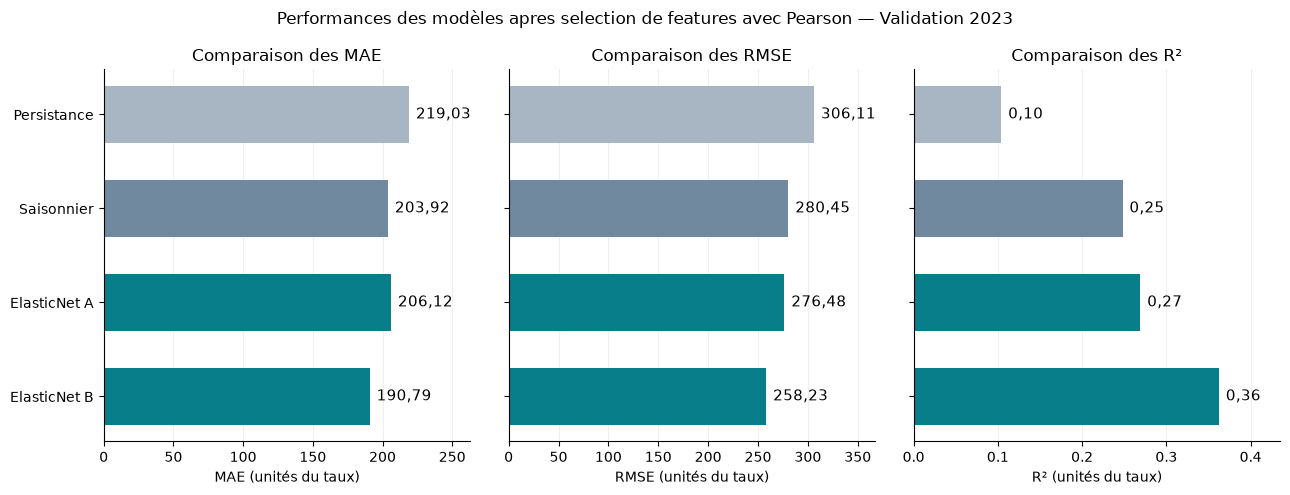

In [52]:
#Summary of results

#calculer les scores per modele
def calculer_scores(nom, reel, prediction):
    return {
        "Modèle": nom,
        "MAE": mean_absolute_error(reel, prediction),
        "RMSE": mean_squared_error(reel, prediction) ** 0.5,
        "R²": r2_score(reel, prediction)
    }

# construction du tableau   

scores = pd.DataFrame([
    calculer_scores("Persistance", y_valid, prediction_persistance),
    calculer_scores("Saisonnier", y_valid, prediction_saisonniere),
    calculer_scores("ElasticNet A", y_valid, prediction_A_baseline),
    calculer_scores("ElasticNet B", y_valid, prediction_B_baseline)
])

# Affichage arrondi, sans modifier les valeurs conservées
display(scores.round({"MAE": 2, "RMSE": 2, "R²": 3}))

#barplot
metrique = "MAE"  # ou "RMSE"
couleurs = ["#A8B5C2", "#71899E", "#087E8B", "#087E8B"]


fig, axes = plt.subplots(1, 3, figsize=(13, 5), sharey=True)

for ax, metrique in zip(axes, ["MAE", "RMSE", "R²"]):
    barres = ax.barh(
        scores["Modèle"],
        scores[metrique],
        color=couleurs,
        height=0.6
    )

    ax.bar_label(
        barres,
        labels=[
            f"{valeur:.2f}".replace(".", ",")
            for valeur in scores[metrique]
        ],
        padding=5,
        fontsize=11
    )

    ax.set_title(f"Comparaison des {metrique}")
    ax.set_xlabel(f"{metrique} (unités du taux)")

    maximum = scores[metrique].max()
    ax.set_xlim(0, maximum * 1.20 if maximum > 0 else 1)

    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)

# Premier modèle en haut ; l'axe est partagé entre les deux graphiques
axes[0].invert_yaxis()

fig.suptitle("Performances des modèles apres selection de features avec Pearson — Validation 2023")
plt.tight_layout()
plt.show()

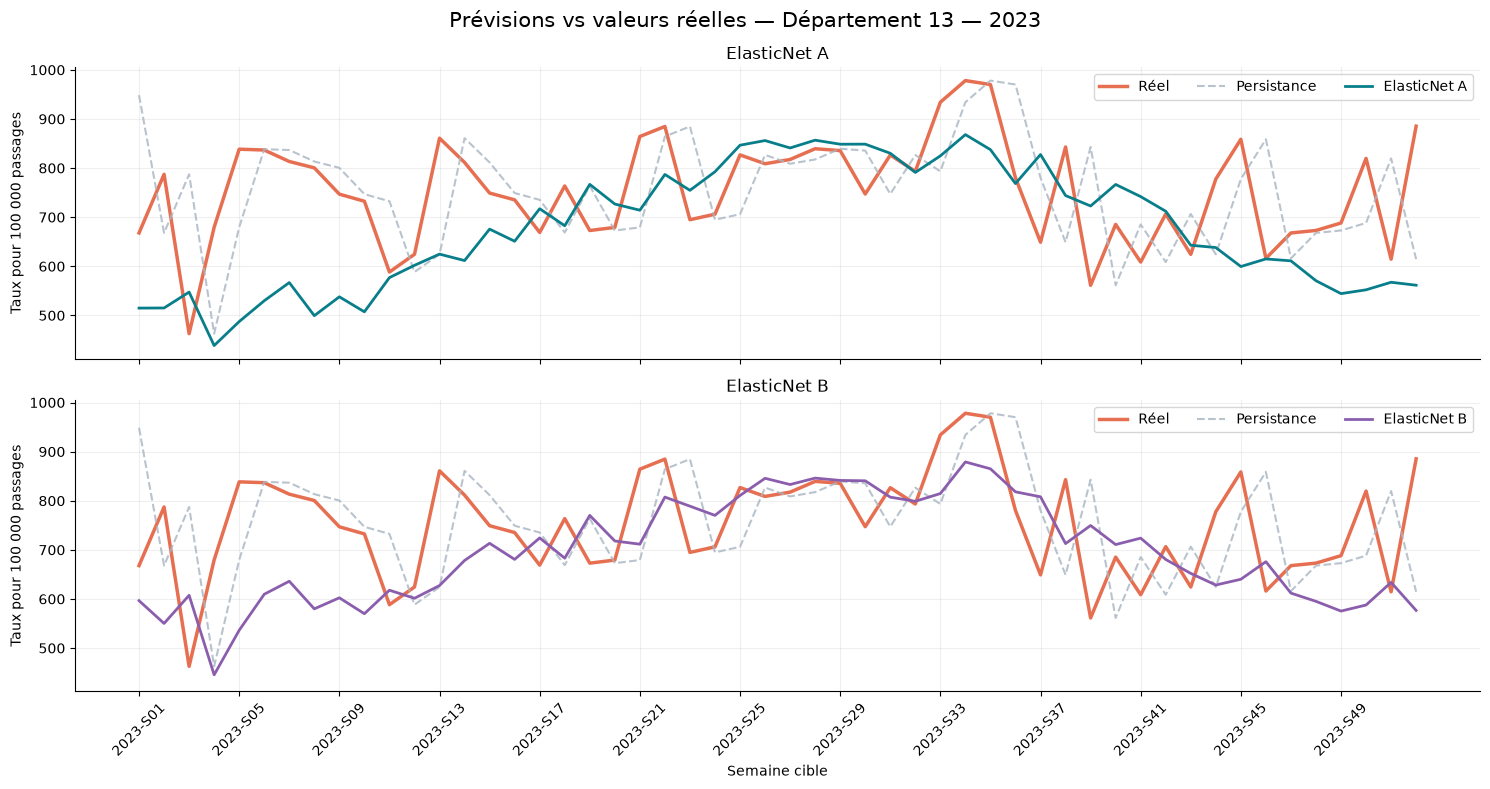

In [53]:

# Comparaison réel vs prédictions

# Choisir le département
dept = "13"

# Regrouper les prédictions
comparaison = valid[["code_dept", "semaine_a_prevoir"]].copy()

comparaison["Taux_precedent"] = valid["taux_connu"]
comparaison["Réel (taux_suivant)"] = y_valid
comparaison["Persistance"] = prediction_persistance
comparaison["ElasticNet A"] = prediction_A_baseline
comparaison["ElasticNet B"] = prediction_B_baseline

# Filtrer le département et trier les semaines
courbes = comparaison[
    comparaison["code_dept"] == dept
].sort_values("semaine_a_prevoir")

# Deux graphiques superposés
fig, axes = plt.subplots(
    2, 1, figsize=(15, 8),
    sharex=True, sharey=True
)

modeles = [
    ("ElasticNet A", "#087E8B"),
    ("ElasticNet B", "#8B5EAD")
]

for ax, (modele, couleur) in zip(axes, modeles):

    ax.plot(
        courbes["semaine_a_prevoir"],
        courbes["Réel (taux_suivant)"],
        label="Réel",
        color="#E76F51",
        linewidth=2.5
    )

    ax.plot(
        courbes["semaine_a_prevoir"],
        courbes["Persistance"],
        label="Persistance",
        color="#A8B5C2",
        linestyle="--",
        linewidth=1.5,
        alpha=0.8
    )

    ax.plot(
        courbes["semaine_a_prevoir"],
        courbes[modele],
        label=modele,
        color=couleur,
        linewidth=2
    )

    ax.set_title(modele)
    ax.set_ylabel("Taux pour 100 000 passages")
    ax.legend(loc="upper right", ncol=3)
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

# Afficher une semaine sur quatre
semaines = courbes["semaine_a_prevoir"].iloc[::4]

axes[-1].set_xticks(semaines)
axes[-1].tick_params(axis="x", rotation=45)
axes[-1].set_xlabel("Semaine cible")

fig.suptitle(
    f"Prévisions vs valeurs réelles — Département {dept} — 2023",
    fontsize=15
)

plt.tight_layout()
plt.show()


on observe:
1. un décalage d'une semaine dans la prediction
2. le modele lisse les pics - pas adapté dans ce forme aux changements rapides

# C. OPTIMISATION DES HYPERPARAMETRES

## 13. Optimisation des hyperparametres avec GridSearchCV


### 13.a. Preparation des données

In [54]:
# Je repars sur data et la separation des données

data = data.copy()

# je fais le trie par anné, semaine, departement
data = data.sort_values(
    ["annee_cible", "semaine_cible", "code_dept"]
).reset_index(drop=True)


#separation train - valid - test
train = data[data["annee_cible"].isin([2021, 2022])].copy()
valid = data[data["annee_cible"] == 2023].copy()
test = data[data["annee_cible"] == 2024].copy()

print("Train :", len(train), "lignes")
print("Validation :", len(valid), "lignes")
print("Test réservé :", len(test), "lignes")



Train : 9888 lignes
Validation : 4992 lignes
Test réservé : 4992 lignes


In [55]:
#Train-test split (X, y) et preparation set A et set B

#colonnes à exclure: date_semaine, semaine_a_prevoir, TousAge_allergie_urgences, "semaine_cos", "semaine_sin" 
# (semaine_cos, semaine_sin sont supprimées pour eviter la multicolinéarité) + colonnes à exclure selon selection de features avec Pearson
exclure_X = [
    "taux_suivant",
    "date_semaine",
    "semaine_a_prevoir",
    "TousAge_allergie_urgences",
   "semaine_cos", "semaine_sin",
    "NH4 in PM1",
    "tp_temps_inconnu",
    "PM2.5",
    "pct_agriculteurs"
]

#Separation X, y A et B
X_train_B = train.drop(columns=exclure_X)
X_valid_B = valid.drop(columns=exclure_X)
X_test_B = test.drop(columns=exclure_X)

X_train_A = X_train_B.drop(columns="taux_connu")
X_valid_A = X_valid_B.drop(columns="taux_connu")
X_test_A = X_test_B.drop(columns="taux_connu")

y_train = train["taux_suivant"]
y_valid = valid["taux_suivant"]
y_test = test["taux_suivant"]

In [56]:

#definition de la fonction de preprocessing pour les colonnes numeriques et categorielle (standardisation et encodage)
from sklearn.compose import ColumnTransformer

def creer_preprocessing(X):

# Colonnes numériques
    numeriques = X.select_dtypes(include="number").columns

# Colonnes à ne pas standardiser
    exclure = [
        "annee", "semaine",
        "tp_tempete_poussiere_chasse_neige",
        "annee_cible", "semaine_cible"
    ]

# Ajouter les colonnes binaires (0/1)
    exclure += [
        col for col in numeriques
        if X_train[col].dropna().isin([0, 1]).all()
    ]
# Conserver les variables à standardiser
    variables_scaler = [col for col in numeriques if col not in exclure]

# Variables conservées sans transformation
    variables_autres = [
        col for col in X_train_B.columns
        if col not in variables_scaler + ["code_dept"]
    ]

    return ColumnTransformer(
        transformers=[
            ("scaler", StandardScaler(), variables_scaler),
            ("encoder", OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ), ["code_dept"])
        ],
        remainder="passthrough"
    )


print("Nombre de colonnes numériques :", len(numeriques))
print("Colonnes numériques :", numeriques.tolist())
print("Colonnes à standardiser :", variables_scaler)
print("Colonnes  exclues de standardisation :", exclure)



Nombre de colonnes numériques : 149
Colonnes numériques : ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'SO2', 'Chl in PM1', 'NO3 in PM1', 'Org in PM1', 'SO4 in PM1', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_tempete_poussiere_chasse_neige', 'TousAge_allergie_urgences', 'prev_Maladie_Respi_Chronique_tsage_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'densite_generalistes', 'densite_pediatres', 'densite_pneumologues', 'densite_allergologues', 'densite_kines', 'annee', 'semaine', 'semaine_sin', 'sem

### 13.b. Fold Temporelle

In [57]:
#Creation de fold temporelle pour crossvalidation

folds_temporels = []

for debut, fin in [(1, 13), (14, 26), (27, 39), (40, 53)]:  #4 periodes de validation

    idx_train = np.where(
        (train["annee_cible"] == 2021) |
        ((train["annee_cible"] == 2022) &
         (train["semaine_cible"] < debut))
    )[0]

    idx_valid = np.where(
        (train["annee_cible"] == 2022) &
        (train["semaine_cible"].between(debut, fin))
    )[0]

    folds_temporels.append((idx_train, idx_valid))

In [58]:
#verification des folds
for i, (idx_train, idx_valid) in enumerate(folds_temporels, 1):

    print(f"\nFold {i}")

    print("Train :", len(idx_train), "observations")
    print("Valid :", len(idx_valid), "observations")

    print("Années train :",
          train.iloc[idx_train]["annee_cible"].unique())

    print("Semaines validation :",
          train.iloc[idx_valid]["semaine_cible"].min(),
          "à",
          train.iloc[idx_valid]["semaine_cible"].max())


Fold 1
Train : 4896 observations
Valid : 1248 observations
Années train : [2021]
Semaines validation : 1 à 13

Fold 2
Train : 6144 observations
Valid : 1248 observations
Années train : [2021 2022]
Semaines validation : 14 à 26

Fold 3
Train : 7392 observations
Valid : 1248 observations
Années train : [2021 2022]
Semaines validation : 27 à 39

Fold 4
Train : 8640 observations
Valid : 1248 observations
Années train : [2021 2022]
Semaines validation : 40 à 52


### 13.c. GridSearchCV

In [59]:
from sklearn.model_selection import GridSearchCV

parameters = {
    "modele__alpha": [0.001, 0.01, 0.1, 1, 10],
    "modele__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9, 1.0]
}

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

def optimiser_elasticnet(X, y):

    pipeline = Pipeline([
        ("preprocessing", creer_preprocessing(X)),
        ("modele", ElasticNet(max_iter=10000))
    ])

    grid=GridSearchCV(
        estimator = pipeline,
        param_grid = parameters,
        cv = folds_temporels,
        scoring = scoring,
        n_jobs = -1,
        refit = "MAE",
    )
    grid.fit(X, y)  

    return grid

# Optimisation des deux modèles
grid_A = optimiser_elasticnet(X_train_A, y_train)
grid_B = optimiser_elasticnet(X_train_B, y_train)


#Resultats
print("Meilleur parametres modele A:", grid_A.best_params_)
print("Meilleur score modele A:", grid_A.best_score_)

print("Meilleurs paramètres B :", grid_B.best_params_)
print("Meilleure MAE B :", grid_B.best_score_)





Meilleur parametres modele A: {'modele__alpha': 0.01, 'modele__l1_ratio': 0.7}
Meilleur score modele A: -194.742144578096
Meilleurs paramètres B : {'modele__alpha': 0.01, 'modele__l1_ratio': 0.1}
Meilleure MAE B : -181.88234035398008


In [60]:
prediction_A_opt = grid_A.predict(X_valid_A)
prediction_B_opt = grid_B.predict(X_valid_B)

afficher_scores("ElasticNet A optimisé", y_valid, prediction_A_opt)
afficher_scores("ElasticNet B optimisé", y_valid, prediction_B_opt)

ElasticNet A optimisé
MAE  : 185.33
RMSE : 250.87
R²   : 0.398
ElasticNet B optimisé
MAE  : 179.58
RMSE : 245.66
R²   : 0.423


### 13.d. Comparision des resultats

In [61]:
#tableau comparatif des scores de 6 modeles sur validation 2023
scores_baseline = scores.copy()


scores_optimises_Grid = pd.DataFrame([
    calculer_scores("ElasticNet A optimisé", y_valid, prediction_A_opt),
    calculer_scores("ElasticNet B optimisé", y_valid, prediction_B_opt)
])

scores_comparaison_Grid = pd.concat(
    [scores_baseline, scores_optimises_Grid],
    ignore_index=True
)

display(scores_comparaison_Grid.round(3))

,Modèle,MAE,RMSE,R²
0,Persistance,219.028,306.108,0.104
1,Saisonnier,203.921,280.451,0.248
2,ElasticNet A,206.120,276.481,0.269
3,ElasticNet B,190.790,258.229,0.362
4,ElasticNet A optimisé,185.325,250.871,0.398
5,ElasticNet B optimisé,179.575,245.656,0.423


In [62]:
scores_comparaison_Grid = scores_comparaison_Grid.sort_values("MAE").reset_index(drop=True)

display(scores_comparaison_Grid.round(3))

,Modèle,MAE,RMSE,R²
0,ElasticNet B optimisé,179.575,245.656,0.423
1,ElasticNet A optimisé,185.325,250.871,0.398
2,ElasticNet B,190.790,258.229,0.362
3,Saisonnier,203.921,280.451,0.248
4,ElasticNet A,206.120,276.481,0.269
5,Persistance,219.028,306.108,0.104


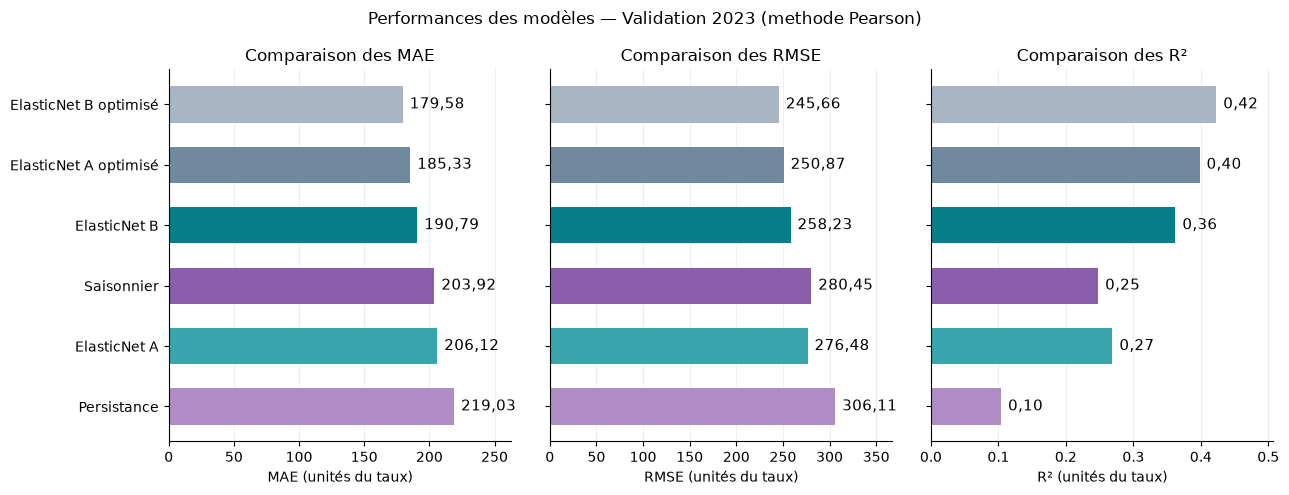

In [63]:
#barplot
metriques = ["MAE", "RMSE", "R²"]

couleurs = [
    "#A8B5C2", "#71899E",
    "#087E8B", "#8B5EAD",
    "#39A5AC", "#B08CC5"]


fig, axes = plt.subplots(1, 3, figsize=(13, 5), sharey=True)

for ax, metrique in zip(axes, ["MAE", "RMSE", "R²"]):
    barres = ax.barh(
        scores_comparaison_Grid["Modèle"],
        scores_comparaison_Grid[metrique],
        color=couleurs,
        height=0.6
    )

    ax.bar_label(
        barres,
        labels=[
            f"{valeur:.2f}".replace(".", ",")
            for valeur in scores_comparaison_Grid[metrique]
        ],
        padding=5,
        fontsize=11
    )

    ax.set_title(f"Comparaison des {metrique}")
    ax.set_xlabel(f"{metrique} (unités du taux)")

    maximum = scores_comparaison_Grid[metrique].max()
    ax.set_xlim(0, maximum * 1.20 if maximum > 0 else 1)

    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)

# Premier modèle en haut ; l'axe est partagé entre les deux graphiques
axes[0].invert_yaxis()

fig.suptitle("Performances des modèles — Validation 2023 (methode Pearson)")
plt.tight_layout()
plt.show()

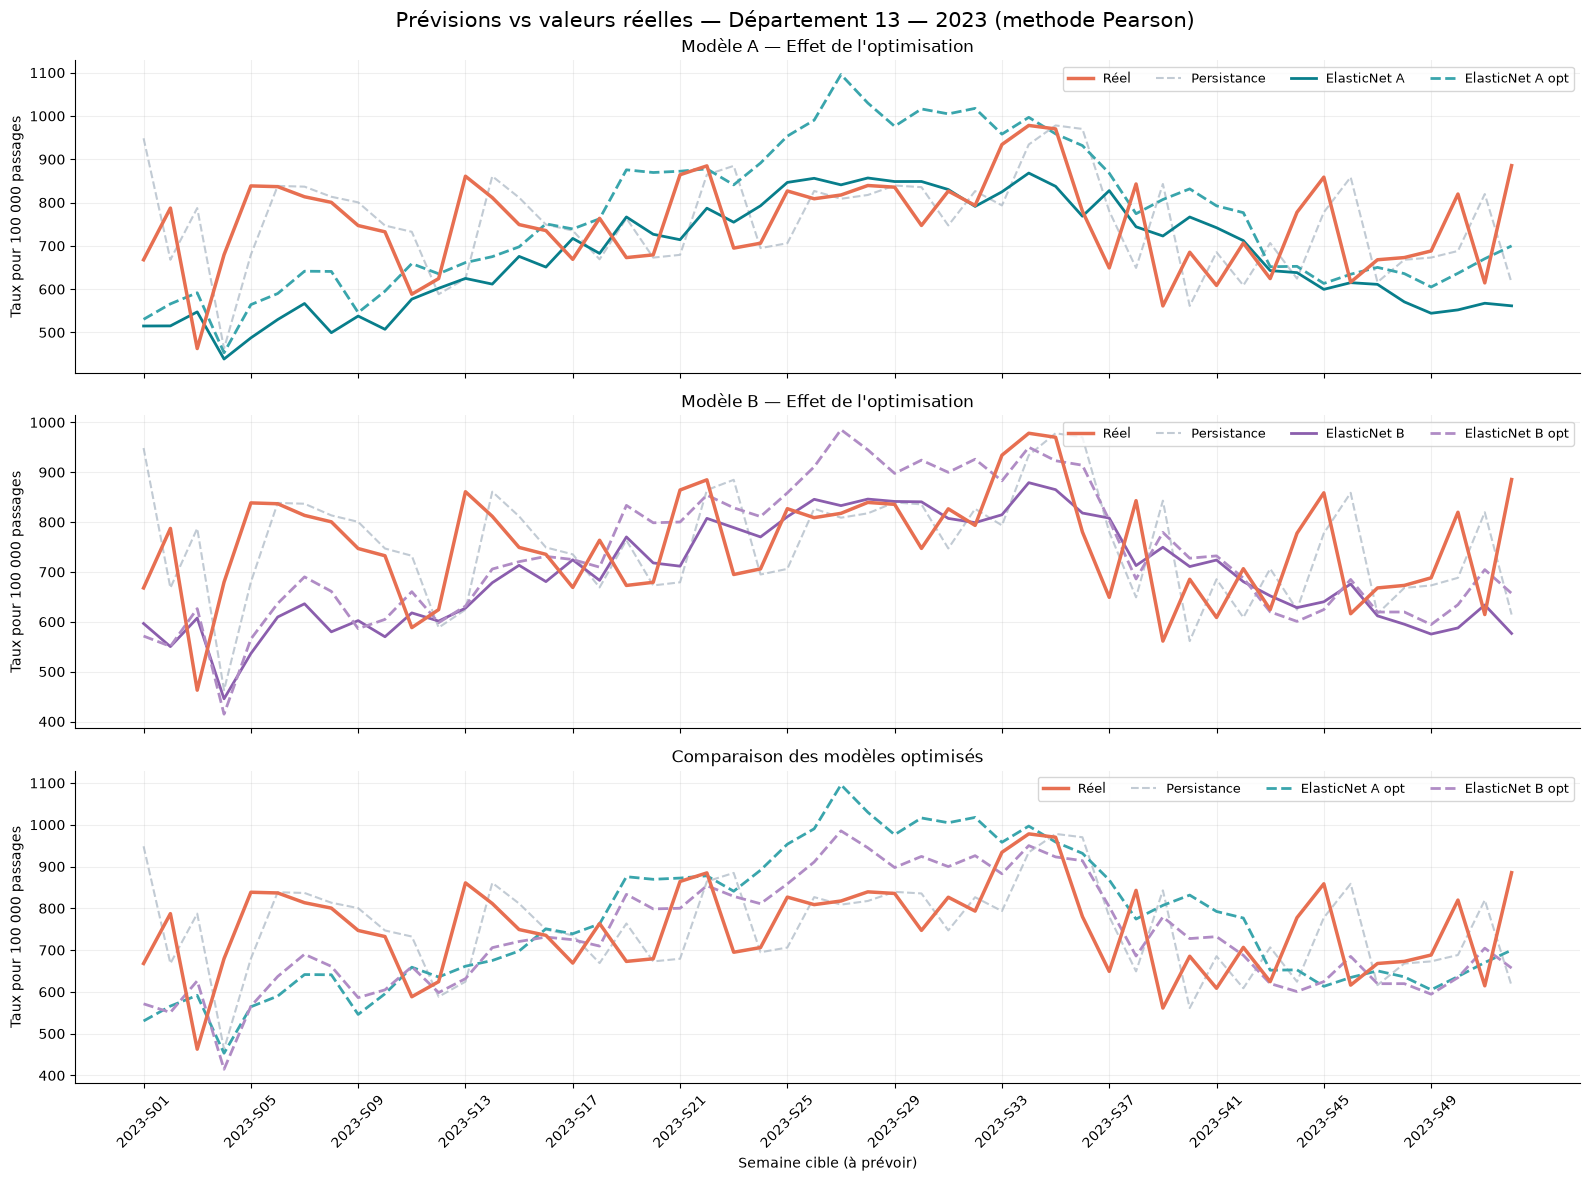

In [64]:

# Comparaison réel vs prédictions

# Choisir le département
dept = "13"

# Regrouper les prédictions
comparaison = valid[["code_dept", "semaine_a_prevoir"]].copy()

comparaison["Réel"] = y_valid
comparaison["Persistance"] = prediction_persistance
comparaison["ElasticNet A"] = prediction_A_baseline
comparaison["ElasticNet B"] = prediction_B_baseline
comparaison["ElasticNet A opt"] = prediction_A_opt
comparaison["ElasticNet B opt"] = prediction_B_opt

# Filtrer et trier les semaines
courbes = comparaison[
    comparaison["code_dept"] == dept
].sort_values("semaine_a_prevoir")

# Configuration des graphiques
groupes = [
    (["ElasticNet A", "ElasticNet A opt"],
     "Modèle A — Effet de l'optimisation"),

    (["ElasticNet B", "ElasticNet B opt"],
     "Modèle B — Effet de l'optimisation"),

    (["ElasticNet A opt", "ElasticNet B opt"],
     "Comparaison des modèles optimisés")
]

couleurs = {
    "ElasticNet A": "#087E8B",
    "ElasticNet A opt": "#39A5AC",
    "ElasticNet B": "#8B5EAD",
    "ElasticNet B opt": "#B08CC5"
}

fig, axes = plt.subplots(
    3, 1, figsize=(16, 12),
    sharex=True
)

for ax, (modeles, titre) in zip(axes, groupes):

    # Valeurs réelles
    ax.plot(
        courbes["semaine_a_prevoir"],
        courbes["Réel"],
        label="Réel",
        color="#E76F51",
        linewidth=2.5,
        zorder=3
    )

    # Baseline de persistance
    ax.plot(
        courbes["semaine_a_prevoir"],
        courbes["Persistance"],
        label="Persistance",
        color="#A8B5C2",
        linestyle="--",
        linewidth=1.5,
        alpha=0.7
    )

    # Modèles à comparer
    for modele in modeles:
        ax.plot(
            courbes["semaine_a_prevoir"],
            courbes[modele],
            label=modele,
            color=couleurs[modele],
            linewidth=2,
            linestyle="--" if "opt" in modele else "-"
        )

    ax.set_title(titre, fontsize=12)
    ax.set_ylabel("Taux pour 100 000 passages")
    ax.legend(loc="upper right", ncol=4, fontsize=9)
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

# Afficher une semaine sur quatre
semaines = courbes["semaine_a_prevoir"].iloc[::4]

axes[-1].set_xticks(semaines)
axes[-1].tick_params(axis="x", rotation=45)
axes[-1].set_xlabel("Semaine cible (à prévoir)")

fig.suptitle(
    f"Prévisions vs valeurs réelles — Département {dept} — 2023 (methode Pearson)",
    fontsize=15
)

plt.tight_layout()
plt.show()
